# EDA 04 · ¿Cada usuario compra barato, caro o en medio dentro de sus opciones?

Para cada compra de `shop.history_events` (60 días):

- **Opciones:** productos de la subcategoría comprada, disponibles en ese momento y que el usuario **no había comprado antes**. En el histórico no hay roturas de stock ni cambios de precio, y todos los productos ya existían.
- **k:** posición del producto comprado al ordenar las opciones de **más caro a más barato**. Los empates de precio cuentan con su rango medio.
- **u = (k − 0,5) / n** ∈ (0, 1): **0 = la opción más cara, 1 = la más barata**.
- **Referencia por popularidad:** E[u] si el usuario eligiera según la popularidad global del producto dentro de su subcategoría. El **residuo r = u − E[u]** separa la preferencia de precio del hecho de que lo barato suela ser lo popular.

Preguntas: (1) ¿la gente compra lo barato de sus opciones? (2) ¿**cada usuario es consistente** (siempre barato, siempre caro, siempre en medio)?

In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt

for p in [Path(".env"), Path("../.env"), Path("../datathon-fme-2026/.env")]:
    if p.exists():
        for line in p.read_text().splitlines():
            k, _, v = line.partition("=")
            if k.strip():
                os.environ.setdefault(k.strip(), v.strip())
        break
API = os.environ.get("RAWTREE_API_URL", "https://api.rawtree.com")
http = requests.Session()
http.headers["Authorization"] = f"Bearer {os.environ['RAWTREE_API_KEY']}"

def sql(q):
    r = http.post(f"{API}/v1/query", json={"sql": q}, timeout=900)
    r.raise_for_status()
    return pd.DataFrame(r.json()["data"])

BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#e8762c", "#1f2328", "#6b7280", "#e5e7eb"
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.edgecolor": GRID, "axes.labelcolor": INK,
                     "xtick.color": MUTED, "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True})
FIG = Path("fig"); FIG.mkdir(exist_ok=True)
rng = np.random.default_rng(0)

## Datos y cálculo de u

In [2]:
cat = sql("SELECT product_id::String AS p, subcategory::String AS sub, price_eur::Float64 AS price FROM shop.catalog")
buys = sql("""SELECT user_id::String AS u, product_id::String AS p, toUnixTimestamp64Milli(ts::DateTime64(3)) AS t
              FROM shop.history_events WHERE event_type::String = 'purchase'""")
buys = buys.merge(cat, on="p").sort_values(["u", "t"]).reset_index(drop=True)
pop = buys.groupby("p").size()
cat["pop"] = cat.p.map(pop).fillna(0)
price_of = dict(zip(cat.p, cat.price))
opts = {s: g[["p", "price", "pop"]].reset_index(drop=True) for s, g in cat.groupby("sub")}

def u_position(price, prices):
    """Posición normalizada (0 = más cara, 1 = más barata) con rango medio para empates."""
    more = (prices > price).sum()
    same = (prices == price).sum()
    k = more + (same + 1) / 2
    return (k - 0.5) / len(prices)

# E[u] si se eligiera por popularidad (con todas las opciones de la subcategoría)
exp_u = {}
for s, g in opts.items():
    uu = np.array([u_position(x, g.price.values) for x in g.price.values])
    w = g["pop"].values + 1.0
    exp_u[s] = float((w * uu).sum() / w.sum())

rows = []
for (user, sub), g in buys.groupby(["u", "sub"], sort=False):
    o = opts[sub]
    bought_before = set()
    for r in g.itertuples():
        avail = o[~o.p.isin(bought_before)] if bought_before else o
        if r.p not in bought_before and len(avail) >= 3:
            rows.append((user, sub, r.t, r.p, u_position(r.price, avail.price.values), len(avail), exp_u[sub]))
        bought_before.add(r.p)
X = pd.DataFrame(rows, columns=["u", "sub", "t", "p", "pos", "n_opciones", "pos_esperada_pop"])
X["resid"] = X.pos - X.pos_esperada_pop
print(f"{len(X):,} compras evaluadas (las recompras y las subcategorías con <3 opciones quedan fuera) · "
      f"{X.u.nunique():,} usuarios".replace(",", "."))
X[["pos", "pos_esperada_pop", "resid", "n_opciones"]].describe().round(3)

464.555 compras evaluadas (las recompras y las subcategorías con <3 opciones quedan fuera) · 51.766 usuarios


,pos,pos_esperada_pop,resid,n_opciones
count,464555.000,464555.000,464555.000,464555.000
mean,0.626,0.633,-0.008,76.954
std,0.297,0.081,0.287,40.631
min,0.003,0.442,-0.798,4.000
25%,0.386,0.567,-0.232,46.000
50%,0.673,0.638,0.053,73.000
75%,0.895,0.708,0.235,104.000
max,0.997,0.863,0.551,184.000


## 1. ¿Se compra lo barato de las opciones?

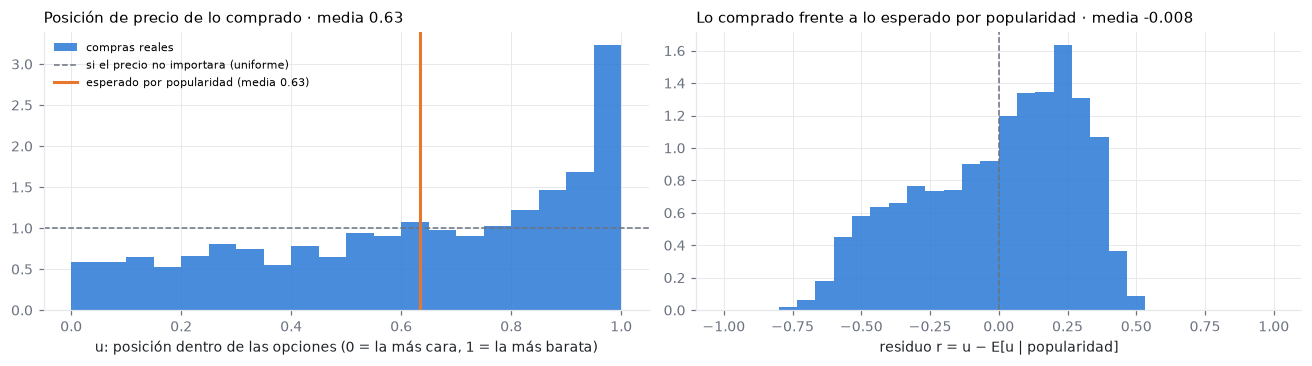

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
axes[0].hist(X.pos, bins=20, range=(0, 1), color=BLUE, alpha=0.85, density=True, label="compras reales")
axes[0].axhline(1, color=MUTED, ls="--", lw=1, label="si el precio no importara (uniforme)")
axes[0].axvline(X.pos_esperada_pop.mean(), color=ORANGE, lw=2, label=f"esperado por popularidad (media {X.pos_esperada_pop.mean():.2f})")
axes[0].set_xlabel("u: posición dentro de las opciones (0 = la más cara, 1 = la más barata)")
axes[0].set_title(f"Posición de precio de lo comprado · media {X.pos.mean():.2f}", loc="left", fontsize=10)
axes[0].legend(frameon=False, fontsize=7.5)
axes[1].hist(X.resid, bins=30, range=(-1, 1), color=BLUE, alpha=0.85, density=True)
axes[1].axvline(0, color=MUTED, ls="--", lw=1)
axes[1].set_xlabel("residuo r = u − E[u | popularidad]")
axes[1].set_title(f"Lo comprado frente a lo esperado por popularidad · media {X.resid.mean():+.3f}", loc="left", fontsize=10)
plt.tight_layout(); plt.savefig(FIG / "precio_posicion_global.png", bbox_inches="tight"); plt.show()

## 2. ¿Cada usuario es consistente?

Usuarios con al menos 6 compras evaluadas. Se reparten sus compras al azar en dos mitades y se correlaciona la media de una mitad con la de la otra entre usuarios (fiabilidad *split-half*), sobre u y sobre el residuo. Como control se hace lo mismo con los usuarios barajados (correlación esperada 0). También se calcula el ICC: qué parte de la varianza de u se explica por el usuario.

In [4]:
cnt = X.groupby("u").size()
Y = X[X.u.isin(cnt[cnt >= 6].index)].copy()
Y["half"] = rng.integers(0, 2, len(Y))
H = Y.groupby(["u", "half"])[["pos", "resid"]].mean().unstack()
H = H.dropna()
r_pos = np.corrcoef(H[("pos", 0)], H[("pos", 1)])[0, 1]
r_res = np.corrcoef(H[("resid", 0)], H[("resid", 1)])[0, 1]
shuf = H[("resid", 1)].sample(frac=1, random_state=1).values
r_null = np.corrcoef(H[("resid", 0)], shuf)[0, 1]
sb = lambda r: 2 * r / (1 + r)                        # Spearman-Brown: fiabilidad de la media completa
# ICC(1) con ANOVA de un factor sobre el residuo
g = Y.groupby("u").resid
k_mean = g.size().mean()
msb = (g.size() * (g.mean() - Y.resid.mean()) ** 2).sum() / (g.ngroups - 1)
msw = ((Y.resid - g.transform("mean")) ** 2).sum() / (len(Y) - g.ngroups)
icc = (msb - msw) / (msb + (k_mean - 1) * msw)
print(f"usuarios con >= 6 compras: {len(H):,} · compras: {len(Y):,}".replace(",", "."))
print(f"split-half u:        r = {r_pos:.3f}  (fiabilidad de la media del usuario {sb(r_pos):.2f})")
print(f"split-half residuo:  r = {r_res:.3f}  (fiabilidad {sb(r_res):.2f})   · control barajado r = {r_null:+.3f}")
print(f"ICC(1) del residuo:  {icc:.3f}  -> el usuario explica el {100 * icc:.1f}% de la varianza de cada compra")

usuarios con >= 6 compras: 24.032 · compras: 392.630
split-half u:        r = 0.519  (fiabilidad de la media del usuario 0.68)
split-half residuo:  r = 0.440  (fiabilidad 0.61)   · control barajado r = +0.005
ICC(1) del residuo:  0.130  -> el usuario explica el 13.0% de la varianza de cada compra


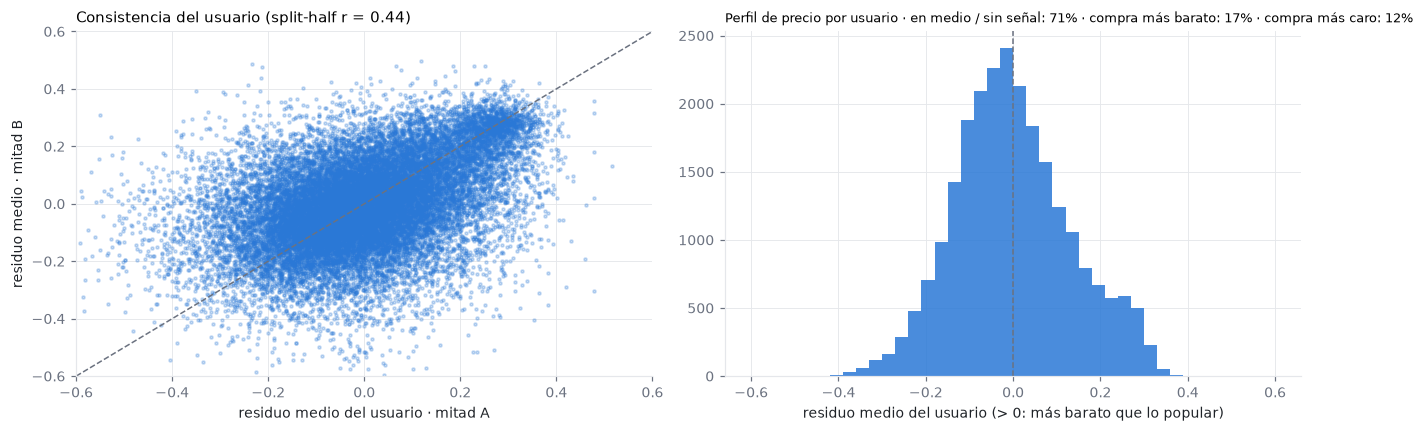

perfil
en medio / sin señal    0.706
compra más barato       0.174
compra más caro         0.120


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ax = axes[0]
ax.scatter(H[("resid", 0)], H[("resid", 1)], s=4, alpha=0.25, color=BLUE)
lim = 0.6
ax.plot([-lim, lim], [-lim, lim], color=MUTED, ls="--", lw=1)
ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
ax.set_xlabel("residuo medio del usuario · mitad A"); ax.set_ylabel("residuo medio · mitad B")
ax.set_title(f"Consistencia del usuario (split-half r = {r_res:.2f})", loc="left", fontsize=10)
um = Y.groupby("u").agg(media=("resid", "mean"), sd=("resid", "std"), n=("resid", "size"))
um["t"] = um.media / (um.sd / np.sqrt(um.n))
um["perfil"] = np.where(um.t > 2, "compra más barato", np.where(um.t < -2, "compra más caro", "en medio / sin señal"))
share = um.perfil.value_counts(normalize=True)
ax = axes[1]
ax.hist(um.media, bins=40, range=(-0.6, 0.6), color=BLUE, alpha=0.85)
ax.axvline(0, color=MUTED, ls="--", lw=1)
ax.set_xlabel("residuo medio del usuario (> 0: más barato que lo popular)")
ax.set_title("Perfil de precio por usuario · " + " · ".join(f"{k}: {v:.0%}" for k, v in share.items()), loc="left", fontsize=8.5)
plt.tight_layout(); plt.savefig(FIG / "precio_consistencia_usuario.png", bbox_inches="tight"); plt.show()
print(share.round(3).to_string())

## 3. ¿Y si se mide en el tiempo? (pasado → futuro)

In [6]:
cut = X.t.quantile(0.75)
P = X[X.t < cut].groupby("u").resid.agg(["mean", "size"]).rename(columns={"mean": "pasado", "size": "n_pasado"})
F = X[X.t >= cut].groupby("u").resid.agg(["mean", "size"]).rename(columns={"mean": "futuro", "size": "n_futuro"})
PF = P.join(F, how="inner")
PF = PF[(PF.n_pasado >= 4) & (PF.n_futuro >= 2)]
print(f"usuarios: {len(PF):,} · corr(residuo pasado, residuo futuro) = {np.corrcoef(PF.pasado, PF.futuro)[0, 1]:.3f}".replace(",", "."))
PF["grupo_pasado"] = pd.qcut(PF.pasado, 5, labels=["quintil 1 (más caro)", "2", "3", "4", "quintil 5 (más barato)"])
PF.groupby("grupo_pasado", observed=True).futuro.agg(["mean", "size"]).round(3)

usuarios: 17.786 · corr(residuo pasado. residuo futuro) = 0.452


,mean,size
grupo_pasado,,
quintil 1 (más caro),-0.093,3558
2,-0.057,3557
3,-0.030,3557
4,0.016,3557
quintil 5 (más barato),0.133,3557
